<a href="https://colab.research.google.com/github/Kushagra14/triton_tutorials/blob/main/Triton_Flash_attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚡ Flash Attention Blocking & $1/\sqrt{d}$ Scaling

---

## 1. Flash Attention: Why Blocks?

### 🧱 The Problem: The HBM Bottleneck
Standard attention calculates the entire score matrix $S = QK^T$, which grows quadratically $O(N^2)$ (e.g., **16 million** elements per head at $N=4096$).
* **Standard Pipeline:** Writes $S$ to High-Bandwidth Memory (HBM) $\rightarrow$ reads it back for softmax $\rightarrow$ writes $P$ back $\rightarrow$ reads it again for $P \cdot V$. This heavy memory traffic is the main system bottleneck.
* **The Flash Attention Solution:** SRAM cache is fast but tiny (100–200 KB per Streaming Multiprocessor). By dividing processing into **blocks**, we perform the entire attention step on-chip, reducing global memory access from $O(N^2)$ to $O(N)$ with zero approximations.

### ⚙️ How the Blocked Loop Works
Think of a **query block** as our target output tile ($P_{\text{id}}$), while we loop through **key/value blocks**:
* $B_r$: Number of query rows per program thread.
* $B_c$: Number of key/value positions processed per step.

To compute softmax incrementally without seeing all scores at once, we track three running statistics per query row:
1. $m$: Running maximum score seen so far.
2. $l$: Running sum of softmax denominators.
3. $O$: Running partial output vector.

### 🔄 The Online Softmax Merge
When a new block of key/value pairs arrives:
1. **Find New Max:** $m_{\text{new}} = \max(m_{\text{old}}, \max(\text{current\_block}))$
2. **Rescale History:** Multiply the old $l$ and $O$ by $e^{m_{\text{old}} - m_{\text{new}}}$ to adjust their scaling relative to the new maximum.
3. **Accumulate Current Block:** Add the current block's contribution scaled to $m_{\text{new}}$.

---

## 2. Where the $1/\sqrt{d}$ Scaling Factor Fits

Scaling must happen **before** exponentiation because $e^{x/\sqrt{d}} \neq \frac{e^x}{\sqrt{d}}$. In hardware kernels, we often fold this directly into the Query tensor $Q$ once before looping starts to save operations:
$$\bar{S}_{\text{block}} = \left( Q_{\text{block}} \cdot \frac{1}{\sqrt{d}} \right) K_{\text{block}}^T$$

---

## 3. Why $\sqrt{d}$? The Mathematical Derivation

### 🎲 The Assumption
Assume each entry in our query vector $q$ and key vector $k$ is an independent random variable with a mean of $0$ and a variance of $1$ (typical at initialization):
$$\mathbb{E}[q_i] = \mathbb{E}[k_i] = 0, \quad \text{Var}(q_i) = \text{Var}(k_i) = 1$$

### 🪜 Step-by-Step Derivation
* **Step 1: One element product**  
  For $q_i k_i$, the variance is:
  $$\text{Var}(q_i k_i) = \mathbb{E}[q_i^2]\mathbb{E}[k_i^2] - (\mathbb{E}[q_i]\mathbb{E}[k_i])^2 = 1 \cdot 1 - 0 = 1$$
* **Step 2: Sum of $d$ elements**  
  For independent variables, variances add. Therefore, the variance of the dot product $s = \sum_{i=1}^{d} q_i k_i$ is:
  $$\text{Var}(s) = d \quad \implies \quad \text{Standard Deviation } (\sigma_s) = \sqrt{d}$$
  For $d=64$, typical raw scores fluctuate wildly around $\pm 8$.
* **Step 3: Normalize by $\sqrt{d}$**  
  Scaling by a constant $c$ changes variance by $c^2$:
  $$\text{Var}\left(\frac{s}{\sqrt{d}}\right) = \frac{\text{Var}(s)}{(\sqrt{d})^2} = \frac{d}{d} = 1$$
  *Dividing by $d$ instead of $\sqrt{d}$ would flatten the variance to $1/d$, which over-smooths the attention map.*

---

## 4. Why Variances Add (and Why Independence Matters)

For two independent random variables $X$ and $Y$ with deviations $a = X - \mu_X$ and $b = Y - \mu_Y$:
$$\text{Var}(X+Y) = \mathbb{E}[a^2] + 2\mathbb{E}[ab] + \mathbb{E}[b^2]$$
Because they are independent, the covariance term splits and cancels to zero:
$$\mathbb{E}[ab] = \mathbb{E}[a]\mathbb{E}[b] = 0 \cdot 0 = 0$$
$$\text{Var}(X+Y) = \text{Var}(X) + \text{Var}(Y)$$

* **Dependent Example (Positive):** If $Y = X$, then $\text{Var}(2X) = 4\text{Var}(X)$ (not $2\text{Var}(X)$).
* **Dependent Example (Negative):** If $Y = -X$, then $X+Y = 0$, so $\text{Var}(0) = 0$.

---

## 5. Why Square to Measure Spread?

Variance averages the squared distance from the mean. Scores are both positive and negative, so a simple linear average cancels out to $0$.
* **Squaring** makes both positive and negative deviations count equally.
* **Why not Absolute Values?** Variances of independent variables add cleanly; mean absolute deviations do not.

---

## 6. Real-World Impact on Softmax Gradients

Softmax applies an exponential to scores. Large unscaled scores create huge gaps, forcing the softmax output to behave like a **one-hot vector** (hard max). The gradient of softmax contains $p(1-p)$, which vanishes to $0$ as $p \to 1$ or $p \to 0$, stalling the learning process.

| Case | Scores | $p(\text{first})$ | Gradient Factor $p(1-p)$ | Learning Health |
| :--- | :--- | :--- | :--- | :--- |
| **$d=2$, Unscaled** | $[2, -2]$ | $0.982$ | $0.018$ | Poor |
| **$d=2$, Scaled** | $[1.41, -1.41]$ | $0.944$ | $0.053$ | Healthy (~3x better) |
| **$d=64$, Unscaled** | $[8, 0]$ | $0.9997$ | $0.0003$ | Stalled |
| **$d=64$, Scaled** | $[1, 0]$ | $0.7300$ | $0.2000$ | Healthy (~600x better) |

## 💡 Core Concept of Flash Attention

**Flash Attention** is an algorithm designed to speed up the attention mechanism in Transformers by making it **hardware-aware**.

### 💾 The GPU Memory Hierarchy
To understand Flash Attention, you need to understand how GPUs handle data:
1. **HBM (High-Bandwidth Memory):** Large capacity (e.g., 40GB–80GB) but relatively slow access speeds. This is the global memory.
2. **SRAM (Static Random-Access Memory):** Extremely small capacity (around 100KB–200KB per Streaming Multiprocessor) but extraordinarily fast (approx. 10x faster than HBM).

### ⚡ Standard Attention vs. Flash Attention
* **Standard Attention (Memory-Bound):** It computes the intermediate $N \times N$ attention matrix $S$, writes it to slow HBM, reads it back to compute softmax, writes the probabilities $P$ back to HBM, and finally reads it back again to multiply by $V$. This makes standard attention **bottlenecked by memory bandwidth, not compute capacity (FLOPs)**.
* **Flash Attention (Compute-Bound):** It never materializes or stores the massive $N \times N$ intermediate matrix in the slow HBM. Instead, it loads chunks of $Q$, $K$, and $V$ into the ultra-fast **SRAM**, computes the attention scores incrementally using **tiling** and **online softmax**, and writes only the final output of size $N \times d$ back to HBM.

By trading slow memory access for a tiny bit of extra on-chip recalculation (recomputation during the backward pass), Flash Attention achieves dramatic speedups (typically **2x to 4x faster**) and significantly reduces memory footprint from $O(N^2)$ to $O(N)$.

## 📈 Scaling of Memory Savings with Sequence Length $N$

The most dramatic benefit of Flash Attention is how its memory consumption scales as input sequences grow longer. Let's analyze the difference in peak memory footprint between Standard Attention and Flash Attention.

### ⚖️ Memory Complexity Comparison

| Method | Memory Complexity | Key Intermediate Variables Stored in HBM | Memory Size for $N=10k, d=64$ (1 Head, FP16) |
| :--- | :--- | :--- | :--- |
| **Standard Attention** | $O(N^2)$ | Attention Scores $S$ ($N \times N$) & Probabilities $P$ ($N \times N$) | ~400 MB |
| **Flash Attention** | $O(N)$ | Output $O$ ($N \times d$), running max $m$, and sum $l$ | ~1.3 MB |

### 🔍 Why the Quadratic $O(N^2)$ Scaling Stalls Standard Attention
In standard attention, storing the complete attention matrix $S = QK^T$ of shape $(N, N)$ requires memory proportional to the square of the sequence length.
* For $N = 1,024$, $N^2 \approx 1$ million elements.
* For $N = 100,000$ (modern long-context LLMs), $N^2 = 10$ billion elements per head. This immediately leads to **Out-Of-Memory (OOM)** errors, even on high-end enterprise GPUs.

### 🛡️ How Flash Attention Achieves Linear $O(N)$ Scaling
Instead of writing the massive $N \times N$ grid to global GPU memory (HBM), Flash Attention processes it block-by-block in ultra-fast, local SRAM.
* At any given point, only a small tile of size $B_r \times B_c$ is held in memory.
* The only tensors written to global memory are the final output $O$ (shape $N \times d$) and a tiny logsumexp vector used for the backward pass (shape $N$).
* Because $d$ (head dimension, usually 64 or 128) is fixed and negligible compared to $N$, the overall memory footprint scales **linearly with $N$**.

### 🚀 Practical Impact
This scaling transformation from $O(N^2)$ to $O(N)$ is what enables modern large language models to process massive contexts (e.g., 32k, 128k, or 1M+ tokens) without needing exponentially larger GPU clusters.

## 🧮 The Complete Flash Attention Algorithm

Below is the exact hardware-aware formulation of **Flash Attention (Forward Pass)** as detailed in the original paper. This algorithm uses tiling to load blocks of inputs from slow HBM (global memory) into fast SRAM, performs attention updates, and writes the output back.

### 📋 Algorithm: Flash Attention Forward Pass

#### **Inputs in HBM:**
* Matrices $Q, K, V \in \mathbb{R}^{N \times d}$ where $N$ is sequence length and $d$ is head dimension.
* SRAM block sizes: $B_c \approx \lceil \frac{M}{4d} \rceil$ and $B_r \approx \min\left(\lceil \frac{M}{4d} \rceil, d\right)$ (where $M$ is the size of SRAM in bytes).

#### **Initialization in HBM:**
1. Initialize output $O = \mathbf{0} \in \mathbb{R}^{N \times d}$.
2. Initialize scaling denominators $l = \mathbf{0} \in \mathbb{R}^N$ and row maximums $m = -\infty \in \mathbb{R}^N$.

---

### 🔄 Step-by-Step Execution Loop

1. **Divide** $Q$ into $T_r = \lceil \frac{N}{B_r} \rceil$ blocks: $Q_1, Q_2, \dots, Q_{T_r}$ of size $B_r \times d$.
2. **Divide** $K, V$ into $T_c = \lceil \frac{N}{B_c} \rceil$ blocks: $K_1, \dots, K_{T_c}$ and $V_1, \dots, V_{T_c}$ of size $B_c \times d$.
3. **Loop over Key-Value Blocks (Outer Loop):**  
   For $j = 1$ to $T_c$:
   * **Load** $K_j, V_j$ from HBM to SRAM.
   * **Loop over Query Blocks (Inner Loop):**  
     For $i = 1$ to $T_r$:
     * **Load** $Q_i, \text{ running statistics } l_i, m_i, \text{ and output } O_i$ from HBM to SRAM.
     * **Compute Scores on SRAM:**
       $$S_{ij} = Q_i K_j^T \in \mathbb{R}^{B_r \times B_c}$$
     * **Find Row Maxima of Current Block:**
       $$\tilde{m}_{ij} = \text{rowmax}(S_{ij}) \in \mathbb{R}^{B_r}$$
     * **Compute Local Unnormalized Exponentials:**
       $$\tilde{P}_{ij} = \exp(S_{ij} - \tilde{m}_{ij}) \in \mathbb{R}^{B_r \times B_c}$$
     * **Compute Local Row Sums:**
       $$\tilde{l}_{ij} = \text{rowsum}(\tilde{P}_{ij}) \in \mathbb{R}^{B_r}$$
     * **Compute Merged Maxima & Rescale Denominators:**
       $$m_i^{\text{new}} = \max(m_i, \tilde{m}_{ij}) \in \mathbb{R}^{B_r}$$
       $$l_i^{\text{new}} = e^{m_i - m_i^{\text{new}}} l_i + e^{tilde{m}_{ij} - m_i^{\text{new}}} \tilde{l}_{ij} \in \mathbb{R}^{B_r}$$
     * **Update and Scale Output Tile $O_i$ on SRAM:**
       $$O_i \leftarrow \text{diag}\left(e^{m_i - m_i^{\text{new}}}\right) O_i + e^{\tilde{m}_{ij} - m_i^{\text{new}}} \tilde{P}_{ij} V_j$$
     * **Write Back Updates to HBM:**
       * Store $O_i \leftarrow \text{diag}(l_i^{\text{new}})^{-1} O_i$ (normalize output elements).
       * Update running tracking matrices: $l_i \leftarrow l_i^{\text{new}}$ and $m_i \leftarrow m_i^{\text{new}}$.

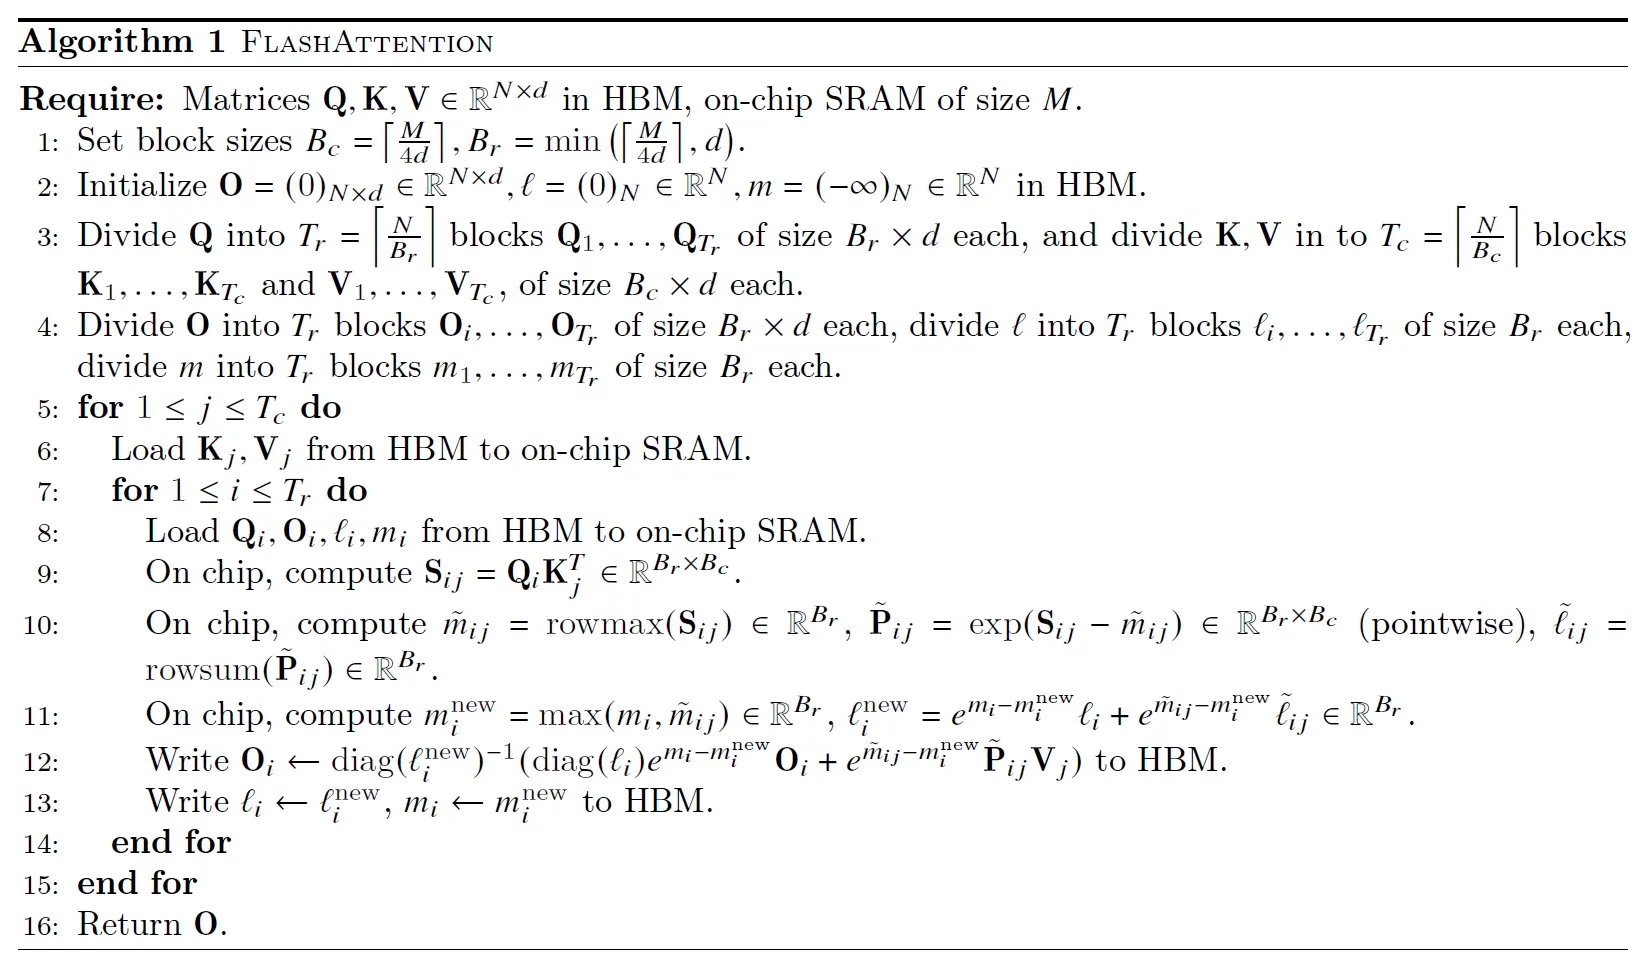

T**he forward chain**

X → Q = XW_Q, K = XW_K, V = XW_V → S = QKᵀ/√d → P = softmax(S) → O = PV → loss

**What backward does**

It starts from dO, the gradient of the loss with respect to O, which arrives from the layers after attention. It then walks the chain in reverse, and each step needs only the local derivative of that step:

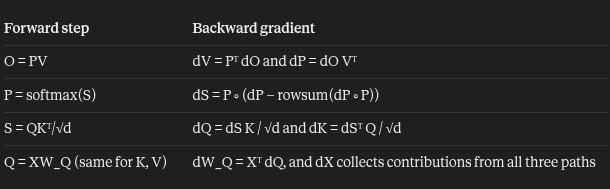

Then the update is W ← W − η · dW. The matrices are only multiplied (with transposes), and nothing is inverted. Softmax could not be inverted anyway, because adding a constant to a row gives the same output.

The softmax step

Softmax mixes the entries of a row, so each score affects every probability in its row. For one row:

dS_ij = P_ij · (dP_ij − Σ_k P_ik · dP_ik)

The sum Σ_k P_ik dP_ik equals rowsum(dO ∘ O) for that row, which flash attention precomputes once per row (often called D_i). That saves recomputing P·dP across the whole row.

**What changes in flash attention**

The backward formulas need P, which is the N × N matrix that flash attention avoided storing in the forward pass. Storing it would bring back the O(N²) memory.

**Flash attention instead recomputes it:**

The forward pass saves only O and one number per row, the log-sum-exp L_i = m_i + log ℓ_i. That is O(N) memory.
In backward, for each tile it recomputes S_ij = Q_i K_jᵀ/√d and then P_ij = exp(S_ij − L_i). It needs no running max here, because L_i already holds the final normalization.
It uses P_ij to get the gradients for that tile, then discards it.

This costs extra FLOPs, since the QKᵀ matmul is done again. But attention is limited by memory traffic, so trading some compute for avoiding N × N reads and writes is a net gain.

**Loop structure**

Following the matmul pattern you already know:

The outer loop goes over key/value blocks j. K_j, V_j and the accumulators dK_j and dV_j stay in registers for the whole inner loop.
The inner loop goes over query blocks i. Each iteration adds to dK_j and dV_j, which is a sum over i.
dQ_i is the awkward one, because every key block contributes to it. FlashAttention-2 accumulates it with atomic adds to HBM. Some implementations use a separate kernel instead.

With a causal mask, masked entries have P = 0, so their gradients are zero, and tiles above the diagonal are skipped just as in the forward pass.

## 📊 Comparative Table: Attention Memory Footprint by Context Length

To visualize how the memory requirements diverge as sequence length ($N$) grows, here is a detailed comparison of standard attention vs. Flash Attention.

### ⚙️ Evaluation Setup
* **Model Parameters:** Assumes a standard LLM configuration with **32 Attention Heads** ($H = 32$), **Head Dimension** ($d = 128$), and **FP16** precision (2 bytes per element).
* **Calculated Values:** Represents the active memory required only for the attention activation tensors during the forward pass.

| Sequence Length ($N$) | Standard Attention Memory ($O(N^2)$) | Flash Attention Memory ($O(N)$) | Memory Saved (Factor) | Hardware Status (Standard Attention) |
| :--- | :--- | :--- | :--- | :--- |
| **2,048 (2k)** | **268 MB** | **33 MB** | **~8x** | Fits easily on any modern GPU |
| **8,192 (8k)** | **4.29 GB** | **134 MB** | **~32x** | Fits on commercial GPUs, limits batch size |
| **16,384 (16k)** | **17.18 GB** | **268 MB** | **~64x** | Requires high-end enterprise GPU (e.g., A100) |
| **32,768 (32k)** | **68.72 GB** | **537 MB** | **~128x** | Out Of Memory (OOM) on standard 40GB GPUs |
| **65,536 (64k)** | **274.88 GB** | **1.07 GB** | **~256x** | Impossible on a single GPU node without splitting |
| **131,072 (128k)** | **1,099.51 GB (1.1 TB)** | **2.15 GB** | **~512x** | Requires massive multi-node tensor parallelism |
| **1,048,576 (1M)** | **70,368.74 GB (70.4 TB)** | **17.18 GB** | **~4,096x** | Physically unfeasible without Flash Attention |

In [1]:
import numpy as np

# Verification of Online Softmax Block-by-Block Merge
# Block 1: [1, 2]
# Block 2: [3, 0]

# 1. Standard Softmax over full array [1, 2, 3, 0]
x = np.array([1.0, 2.0, 3.0, 0.0])
std_max = np.max(x)
std_exp = np.exp(x - std_max)
std_denom = np.sum(std_exp)
std_softmax = std_exp / std_denom
print("=== Standard Softmax ===")
print(f"Max: {std_max}")
print(f"Denominator: {std_denom}")
print(f"Probabilities: {std_softmax}\n")

# 2. Online Softmax Merge
# Step 1: Process Block 1 [1, 2]
b1 = np.array([1.0, 2.0])
m1 = np.max(b1)
l1 = np.sum(np.exp(b1 - m1))

# Step 2: Process Block 2 [3, 0]
b2 = np.array([3.0, 0.0])
m2 = np.max(b2)
l2 = np.sum(np.exp(b2 - m2))

# Step 3: Merge Block 1 and Block 2
m_merged = max(m1, m2)
l_merged = l1 * np.exp(m1 - m_merged) + l2 * np.exp(m2 - m_merged)

print("=== Online Softmax Merge ===")
print(f"Block 1 max (m1): {m1}, local denominator (l1): {l1}")
print(f"Block 2 max (m2): {m2}, local denominator (l2): {l2}")
print(f"Merged max (m_merged): {m_merged}")
print(f"Merged denominator (l_merged): {l_merged}")
print(f"Does denominator match standard? {np.isclose(std_denom, l_merged)}")

=== Standard Softmax ===
Max: 3.0
Denominator: 1.553001792775919
Probabilities: [0.08714432 0.23688282 0.64391426 0.0320586 ]

=== Online Softmax Merge ===
Block 1 max (m1): 2.0, local denominator (l1): 1.3678794411714423
Block 2 max (m2): 3.0, local denominator (l2): 1.0497870683678638
Merged max (m_merged): 3.0
Merged denominator (l_merged): 1.5530017927759188
Does denominator match standard? True


🎭 **What is "Staging" in Triton and Flash Attention?**

In high-performance GPU kernels like the Triton implementation in your notebook, Staging (specifically referred to in variables like STAGE or num_stages) refers to two distinct but related concepts depending on whether you look at the mathematical algorithm or the hardware optimization level:

1. Mathematical Staging: Masked vs. Unmasked Tiles
In your Triton code, you see STAGE: tl.constexpr being used to decide which parts of the attention matrix to compute:



```
if STAGE & 1:  # Stage 1: Off-band (fully unmasked)
    # Computes blocks that are completely below the causal diagonal.
    # No masking logic is needed here, making it faster!
if STAGE & 2:  # Stage 2: On-band (partially masked / diagonal)
    # Computes blocks that cross the causal diagonal line.
    # It applies the causal mask to ensure tokens don't look at future tokens.
```


  **Note:** Why split into stages? Applying a mask on GPUs requires conditional logic (tl.where), which introduces overhead. By separating the computation into Staging 1 (unmasked/off-band) and Staging 2 (masked/on-band), the kernel can run the unmasked blocks at maximum hardware speed without wasting cycles on masking checks.




2. Hardware Staging: Software Pipelining (num_stages)
In modern GPUs (like NVIDIA Ampere, Hopper, and Blackwell), the GPU has dedicated asynchronous copy engines that can move data from Global Memory (HBM) to on-chip Shared Memory (SRAM) while the Tensor Cores are busy performing math.

When you configure num_stages=s (e.g., num_stages=3 or 4 in your Triton configs):

**Double/Triple Buffering**: Instead of waiting for a tile of $K$$K$ and $V$$V$ to load, starting the math, and then waiting for the next tile, the hardware creates a "pipeline" of multiple stages.
How it operates:
Stage 0: Tensor Cores are calculating matrix multiplication on the current tile in SRAM.
Stage 1: The hardware is actively pre-fetching the next tile of $K$$K$ and $V$$V$ from HBM into another buffer in SRAM.
Stage 2: The next-next tile's memory request is being issued.
This hides memory latency entirely behind computation, keeping the GPU's execution units at 100% utilizatio

In [ ]:
import pytest
import torch
import os

import triton
import triton.language as tl
from triton.tools.tensor_descriptor import TensorDescriptor

DEVICE = triton.runtime.driver.active.get_active_torch_device()


def is_hip():
    return triton.runtime.driver.active.get_current_target().backend == "hip"


def is_cuda():
    return triton.runtime.driver.active.get_current_target().backend == "cuda"


def supports_host_descriptor():
    return is_cuda() and torch.cuda.get_device_capability()[0] >= 9


def is_blackwell():
    return is_cuda() and torch.cuda.get_device_capability()[0] == 10


def is_hopper():
    return is_cuda() and torch.cuda.get_device_capability()[0] == 9


@triton.jit
def _attn_fwd_inner(acc, l_i, m_i, q,  #
                    desc_k, desc_v,  #
                    off_hz, dtype: tl.constexpr, start_m, qk_scale,  #
                    BLOCK_M: tl.constexpr, HEAD_DIM: tl.constexpr, BLOCK_N: tl.constexpr,  #
                    STAGE: tl.constexpr, offs_m: tl.constexpr, offs_n: tl.constexpr,  #
                    N_CTX: tl.constexpr, warp_specialize: tl.constexpr, IS_HOPPER: tl.constexpr):
    # range of values handled by this stage
    if STAGE == 1:
        lo, hi = 0, start_m * BLOCK_M
    elif STAGE == 2:
        lo, hi = start_m * BLOCK_M, (start_m + 1) * BLOCK_M
        lo = tl.multiple_of(lo, BLOCK_M)
    # causal = False
    else:
        lo, hi = 0, N_CTX
    offset_y = off_hz * N_CTX
    offsetk_y = offset_y + lo
    offsetv_y = offset_y + lo
    # loop over k, v and update accumulator
    for start_n in tl.range(lo, hi, BLOCK_N, warp_specialize=warp_specialize):
        start_n = tl.multiple_of(start_n, BLOCK_N)
        # -- compute qk ----
        k = desc_k.load([offsetk_y, 0]).T
        qk = tl.dot(q, k)
        if STAGE == 2:
            mask = offs_m[:, None] >= (start_n + offs_n[None, :])
            qk = qk * qk_scale + tl.where(mask, 0, -1.0e6)
            m_ij = tl.maximum(m_i, tl.max(qk, 1))
            qk -= m_ij[:, None]
        else:
            m_ij = tl.maximum(m_i, tl.max(qk, 1) * qk_scale)
            qk = qk * qk_scale - m_ij[:, None]
        p = tl.math.exp2(qk)
        # -- compute correction factor
        alpha = tl.math.exp2(m_i - m_ij)
        l_ij = tl.sum(p, 1)
        # -- update output accumulator --
        if not IS_HOPPER and warp_specialize and BLOCK_M == 128 and HEAD_DIM == 128:
            BM: tl.constexpr = acc.shape[0]
            BN: tl.constexpr = acc.shape[1]
            acc0, acc1 = acc.reshape([BM, 2, BN // 2]).permute(0, 2, 1).split()
            acc0 = acc0 * alpha[:, None]
            acc1 = acc1 * alpha[:, None]
            acc = tl.join(acc0, acc1).permute(0, 2, 1).reshape([BM, BN])
        else:
            acc = acc * alpha[:, None]
        # prepare p and v for the dot
        if dtype == tl.float8e5:
            v = desc_v.load([off_hz * HEAD_DIM, start_n]).T
        else:
            v = desc_v.load([offsetv_y, 0])
        p = p.to(dtype)
        # note that this non transposed v for FP8 is only supported on Blackwell
        acc = tl.dot(p, v, acc)
        # update m_i and l_i
        # place this at the end of the loop to reduce register pressure
        l_i = l_i * alpha + l_ij
        m_i = m_ij
        offsetk_y += BLOCK_N
        offsetv_y += BLOCK_N
    return acc, l_i, m_i


def _host_descriptor_pre_hook(nargs):
    BLOCK_M = nargs["BLOCK_M"]
    BLOCK_N = nargs["BLOCK_N"]
    HEAD_DIM = nargs["HEAD_DIM"]
    if not isinstance(nargs["desc_q"], TensorDescriptor):
        return
    nargs["desc_q"].block_shape = [BLOCK_M, HEAD_DIM]
    if nargs["FP8_OUTPUT"]:
        nargs["desc_v"].block_shape = [HEAD_DIM, BLOCK_N]
    else:
        nargs["desc_v"].block_shape = [BLOCK_N, HEAD_DIM]
    nargs["desc_k"].block_shape = [BLOCK_N, HEAD_DIM]
    nargs["desc_o"].block_shape = [BLOCK_M, HEAD_DIM]


if is_hip():
    NUM_STAGES_OPTIONS = [1]
elif supports_host_descriptor():
    NUM_STAGES_OPTIONS = [2, 3, 4]
else:
    NUM_STAGES_OPTIONS = [2, 3, 4]

configs = [
    triton.Config({'BLOCK_M': BM, 'BLOCK_N': BN}, num_stages=s, num_warps=w, pre_hook=_host_descriptor_pre_hook) \
    for BM in [64, 128]\
    for BN in [32, 64, 128]\
    for s in NUM_STAGES_OPTIONS \
    for w in [4, 8]\
]
if "PYTEST_VERSION" in os.environ:
    # Use a single config in testing for reproducibility
    configs = [
        triton.Config(dict(BLOCK_M=128, BLOCK_N=64), num_stages=2, num_warps=4, pre_hook=_host_descriptor_pre_hook),
    ]


def keep(conf):
    BLOCK_M = conf.kwargs["BLOCK_M"]
    BLOCK_N = conf.kwargs["BLOCK_N"]
    return not (is_cuda() and torch.cuda.get_device_capability()[0] == 9 and BLOCK_M * BLOCK_N < 128 * 128
                and conf.num_warps == 8)


def prune_invalid_configs(configs, named_args, **kwargs):
    N_CTX = kwargs["N_CTX"]
    STAGE = kwargs["STAGE"]

    # Filter out configs where BLOCK_M > N_CTX
    # Filter out configs where BLOCK_M < BLOCK_N when causal is True
    return [
        conf for conf in configs if conf.kwargs.get("BLOCK_M", 0) <= N_CTX and (
            conf.kwargs.get("BLOCK_M", 0) >= conf.kwargs.get("BLOCK_N", 0) or STAGE == 1)
    ]


@triton.jit
def _maybe_make_tensor_desc(desc_or_ptr, shape, strides, block_shape):
    if isinstance(desc_or_ptr, tl.tensor_descriptor):
        return desc_or_ptr
    else:
        return tl.make_tensor_descriptor(desc_or_ptr, shape, strides, block_shape)


@triton.autotune(configs=list(filter(keep, configs)), key=["N_CTX", "HEAD_DIM", "FP8_OUTPUT", "warp_specialize"],
                 prune_configs_by={'early_config_prune': prune_invalid_configs})
@triton.jit
def _attn_fwd(sm_scale, M,  #
              Z, H, desc_q, desc_k, desc_v, desc_o, N_CTX,  #
              HEAD_DIM: tl.constexpr,  #
              BLOCK_M: tl.constexpr,  #
              BLOCK_N: tl.constexpr,  #
              FP8_OUTPUT: tl.constexpr,  #
              STAGE: tl.constexpr,  #
              warp_specialize: tl.constexpr,  #
              IS_HOPPER: tl.constexpr,  #
              ):
    dtype = tl.float8e5 if FP8_OUTPUT else tl.float16
    tl.static_assert(BLOCK_N <= HEAD_DIM)
    start_m = tl.program_id(0)
    off_hz = tl.program_id(1)
    off_z = off_hz // H
    off_h = off_hz % H

    y_dim = Z * H * N_CTX
    desc_q = _maybe_make_tensor_desc(desc_q, shape=[y_dim, HEAD_DIM], strides=[HEAD_DIM, 1],
                                     block_shape=[BLOCK_M, HEAD_DIM])
    if FP8_OUTPUT:
        desc_v = _maybe_make_tensor_desc(desc_v, shape=[Z * H * HEAD_DIM, N_CTX], strides=[N_CTX, 1],
                                         block_shape=[HEAD_DIM, BLOCK_N])
    else:
        desc_v = _maybe_make_tensor_desc(desc_v, shape=[y_dim, HEAD_DIM], strides=[HEAD_DIM, 1],
                                         block_shape=[BLOCK_N, HEAD_DIM])
    desc_k = _maybe_make_tensor_desc(desc_k, shape=[y_dim, HEAD_DIM], strides=[HEAD_DIM, 1],
                                     block_shape=[BLOCK_N, HEAD_DIM])
    desc_o = _maybe_make_tensor_desc(desc_o, shape=[y_dim, HEAD_DIM], strides=[HEAD_DIM, 1],
                                     block_shape=[BLOCK_M, HEAD_DIM])

    offset_y = off_z * (N_CTX * H) + off_h * N_CTX
    qo_offset_y = offset_y + start_m * BLOCK_M
    # initialize offsets
    offs_m = start_m * BLOCK_M + tl.arange(0, BLOCK_M)
    offs_n = tl.arange(0, BLOCK_N)
    # initialize pointer to m and l
    m_i = tl.zeros([BLOCK_M], dtype=tl.float32) - float("inf")
    l_i = tl.zeros([BLOCK_M], dtype=tl.float32) + 1.0
    acc = tl.zeros([BLOCK_M, HEAD_DIM], dtype=tl.float32)
    # load scales
    qk_scale = sm_scale
    qk_scale *= 1.44269504  # 1/log(2)
    # load q: it will stay in SRAM throughout
    q = desc_q.load([qo_offset_y, 0])
    # stage 1: off-band
    # For causal = True, STAGE = 3 and _attn_fwd_inner gets 1 as its STAGE
    # For causal = False, STAGE = 1, and _attn_fwd_inner gets 3 as its STAGE
    if STAGE & 1:
        acc, l_i, m_i = _attn_fwd_inner(acc, l_i, m_i, q,  #
                                        desc_k, desc_v,  #
                                        off_hz, dtype, start_m, qk_scale,  #
                                        BLOCK_M, HEAD_DIM, BLOCK_N,  #
                                        4 - STAGE, offs_m, offs_n, N_CTX,  #
                                        warp_specialize, IS_HOPPER)
    # stage 2: on-band
    if STAGE & 2:
        acc, l_i, m_i = _attn_fwd_inner(acc, l_i, m_i, q,  #
                                        desc_k, desc_v,  #
                                        off_hz, dtype, start_m, qk_scale,  #
                                        BLOCK_M, HEAD_DIM, BLOCK_N,  #
                                        2, offs_m, offs_n, N_CTX,  #
                                        warp_specialize, IS_HOPPER)
    # epilogue
    m_i += tl.math.log2(l_i)
    acc = acc / l_i[:, None]
    m_ptrs = M + off_hz * N_CTX + offs_m
    tl.store(m_ptrs, m_i)
    desc_o.store([qo_offset_y, 0], acc.to(dtype))


@triton.jit
def _attn_bwd_preprocess(O, DO,  #
                         Delta,  #
                         Z, H, N_CTX,  #
                         BLOCK_M: tl.constexpr, HEAD_DIM: tl.constexpr  #
                         ):
    off_m = tl.program_id(0) * BLOCK_M + tl.arange(0, BLOCK_M)
    off_hz = tl.program_id(1)
    off_n = tl.arange(0, HEAD_DIM)
    # load
    o = tl.load(O + off_hz * HEAD_DIM * N_CTX + off_m[:, None] * HEAD_DIM + off_n[None, :])
    do = tl.load(DO + off_hz * HEAD_DIM * N_CTX + off_m[:, None] * HEAD_DIM + off_n[None, :]).to(tl.float32)
    delta = tl.sum(o * do, axis=1)
    # write-back
    tl.store(Delta + off_hz * N_CTX + off_m, delta)


# The main inner-loop logic for computing dK and dV.
@triton.jit
def _attn_bwd_dkdv(dk, dv,  #
                   Q, k, v, sm_scale,  #
                   DO,  #
                   M, D,  #
                   # shared by Q/K/V/DO.
                   stride_tok, stride_d,  #
                   H, N_CTX, BLOCK_M1: tl.constexpr,  #
                   BLOCK_N1: tl.constexpr,  #
                   HEAD_DIM: tl.constexpr,  #
                   # Filled in by the wrapper.
                   start_n, start_m, num_steps,  #
                   MASK: tl.constexpr):
    offs_m = start_m + tl.arange(0, BLOCK_M1)
    offs_n = start_n + tl.arange(0, BLOCK_N1)
    offs_k = tl.arange(0, HEAD_DIM)
    qT_ptrs = Q + offs_m[None, :] * stride_tok + offs_k[:, None] * stride_d
    do_ptrs = DO + offs_m[:, None] * stride_tok + offs_k[None, :] * stride_d
    # BLOCK_N1 must be a multiple of BLOCK_M1, otherwise the code wouldn't work.
    tl.static_assert(BLOCK_N1 % BLOCK_M1 == 0)
    curr_m = start_m
    step_m = BLOCK_M1
    for blk_idx in range(num_steps):
        qT = tl.load(qT_ptrs)
        # Load m before computing qk to reduce pipeline stall.
        offs_m = curr_m + tl.arange(0, BLOCK_M1)
        m = tl.load(M + offs_m)
        qkT = tl.dot(k, qT)
        pT = tl.math.exp2(qkT - m[None, :])
        # Autoregressive masking.
        if MASK:
            mask = (offs_m[None, :] >= offs_n[:, None])
            pT = tl.where(mask, pT, 0.0)
        do = tl.load(do_ptrs)
        # Compute dV.
        ppT = pT
        ppT = ppT.to(tl.float16)
        dv += tl.dot(ppT, do)
        # D (= delta) is pre-divided by ds_scale.
        Di = tl.load(D + offs_m)
        # Compute dP and dS.
        dpT = tl.dot(v, tl.trans(do)).to(tl.float32)
        dsT = pT * (dpT - Di[None, :])
        dsT = dsT.to(tl.float16)
        dk += tl.dot(dsT, tl.trans(qT))
        # Increment pointers.
        curr_m += step_m
        qT_ptrs += step_m * stride_tok
        do_ptrs += step_m * stride_tok
    return dk, dv


# the main inner-loop logic for computing dQ
@triton.jit
def _attn_bwd_dq(dq, q, K, V,  #
                 do, m, D,
                 # shared by Q/K/V/DO.
                 stride_tok, stride_d,  #
                 H, N_CTX,  #
                 BLOCK_M2: tl.constexpr,  #
                 BLOCK_N2: tl.constexpr,  #
                 HEAD_DIM: tl.constexpr,
                 # Filled in by the wrapper.
                 start_m, start_n, num_steps,  #
                 MASK: tl.constexpr):
    offs_m = start_m + tl.arange(0, BLOCK_M2)
    offs_n = start_n + tl.arange(0, BLOCK_N2)
    offs_k = tl.arange(0, HEAD_DIM)
    kT_ptrs = K + offs_n[None, :] * stride_tok + offs_k[:, None] * stride_d
    vT_ptrs = V + offs_n[None, :] * stride_tok + offs_k[:, None] * stride_d
    # D (= delta) is pre-divided by ds_scale.
    Di = tl.load(D + offs_m)
    # BLOCK_M2 must be a multiple of BLOCK_N2, otherwise the code wouldn't work.
    tl.static_assert(BLOCK_M2 % BLOCK_N2 == 0)
    curr_n = start_n
    step_n = BLOCK_N2
    for blk_idx in range(num_steps):
        kT = tl.load(kT_ptrs)
        vT = tl.load(vT_ptrs)
        qk = tl.dot(q, kT)
        p = tl.math.exp2(qk - m)
        # Autoregressive masking.
        if MASK:
            offs_n = curr_n + tl.arange(0, BLOCK_N2)
            mask = (offs_m[:, None] >= offs_n[None, :])
            p = tl.where(mask, p, 0.0)
        # Compute dP and dS.
        dp = tl.dot(do, vT).to(tl.float32)
        ds = p * (dp - Di[:, None])
        ds = ds.to(tl.float16)
        # Compute dQ.
        # NOTE: We need to de-scale dq in the end, because kT was pre-scaled.
        dq += tl.dot(ds, tl.trans(kT))
        # Increment pointers.
        curr_n += step_n
        kT_ptrs += step_n * stride_tok
        vT_ptrs += step_n * stride_tok
    return dq


@triton.jit
def _attn_bwd(Q, K, V, sm_scale,  #
              DO,  #
              DQ, DK, DV,  #
              M, D,
              # shared by Q/K/V/DO.
              stride_z, stride_h, stride_tok, stride_d,  #
              H, N_CTX,  #
              BLOCK_M1: tl.constexpr,  #
              BLOCK_N1: tl.constexpr,  #
              BLOCK_M2: tl.constexpr,  #
              BLOCK_N2: tl.constexpr,  #
              BLK_SLICE_FACTOR: tl.constexpr,  #
              HEAD_DIM: tl.constexpr,  #
              CAUSAL: tl.constexpr):
    LN2: tl.constexpr = 0.6931471824645996  # = ln(2)

    bhid = tl.program_id(2)
    off_chz = (bhid * N_CTX).to(tl.int64)
    adj = (stride_h * (bhid % H) + stride_z * (bhid // H)).to(tl.int64)
    pid = tl.program_id(0)

    # offset pointers for batch/head
    Q += adj
    K += adj
    V += adj
    DO += adj
    DQ += adj
    DK += adj
    DV += adj
    M += off_chz
    D += off_chz

    # load scales
    offs_k = tl.arange(0, HEAD_DIM)

    start_n = pid * BLOCK_N1
    start_m = 0

    MASK_BLOCK_M1: tl.constexpr = BLOCK_M1 // BLK_SLICE_FACTOR
    offs_n = start_n + tl.arange(0, BLOCK_N1)

    dv = tl.zeros([BLOCK_N1, HEAD_DIM], dtype=tl.float32)
    dk = tl.zeros([BLOCK_N1, HEAD_DIM], dtype=tl.float32)

    # load K and V: they stay in SRAM throughout the inner loop.
    k = tl.load(K + offs_n[:, None] * stride_tok + offs_k[None, :] * stride_d)
    v = tl.load(V + offs_n[:, None] * stride_tok + offs_k[None, :] * stride_d)

    if CAUSAL:
        start_m = start_n
        num_steps = BLOCK_N1 // MASK_BLOCK_M1
        dk, dv = _attn_bwd_dkdv(dk, dv,  #
                                Q, k, v, sm_scale,  #
                                DO,  #
                                M, D,  #
                                stride_tok, stride_d,  #
                                H, N_CTX,  #
                                MASK_BLOCK_M1, BLOCK_N1, HEAD_DIM,  #
                                start_n, start_m, num_steps,  #
                                MASK=True,  #
                                )

        start_m += num_steps * MASK_BLOCK_M1

    # Compute dK and dV for non-masked blocks.
    num_steps = (N_CTX - start_m) // BLOCK_M1
    dk, dv = _attn_bwd_dkdv(  #
        dk, dv,  #
        Q, k, v, sm_scale,  #
        DO,  #
        M, D,  #
        stride_tok, stride_d,  #
        H, N_CTX,  #
        BLOCK_M1, BLOCK_N1, HEAD_DIM,  #
        start_n, start_m, num_steps,  #
        MASK=False,  #
    )

    dv_ptrs = DV + offs_n[:, None] * stride_tok + offs_k[None, :] * stride_d
    tl.store(dv_ptrs, dv)

    # Write back dK.
    dk *= sm_scale
    dk_ptrs = DK + offs_n[:, None] * stride_tok + offs_k[None, :] * stride_d
    tl.store(dk_ptrs, dk)

    # THIS BLOCK DOES DQ:
    start_m = pid * BLOCK_M2
    start_n = 0
    num_steps = N_CTX // BLOCK_N2

    MASK_BLOCK_N2: tl.constexpr = BLOCK_N2 // BLK_SLICE_FACTOR
    offs_m = start_m + tl.arange(0, BLOCK_M2)

    q = tl.load(Q + offs_m[:, None] * stride_tok + offs_k[None, :] * stride_d)
    dq = tl.zeros([BLOCK_M2, HEAD_DIM], dtype=tl.float32)
    do = tl.load(DO + offs_m[:, None] * stride_tok + offs_k[None, :] * stride_d)

    m = tl.load(M + offs_m)
    m = m[:, None]

    if CAUSAL:
        # Compute dQ for masked (diagonal) blocks.
        # NOTE: This code scans each row of QK^T backward (from right to left,
        # but inside each call to _attn_bwd_dq, from left to right), but that's
        # not due to anything important.  I just wanted to reuse the loop
        # structure for dK & dV above as much as possible.
        end_n = start_m + BLOCK_M2
        num_steps = BLOCK_M2 // MASK_BLOCK_N2
        dq = _attn_bwd_dq(dq, q, K, V,  #
                          do, m, D,  #
                          stride_tok, stride_d,  #
                          H, N_CTX,  #
                          BLOCK_M2, MASK_BLOCK_N2, HEAD_DIM,  #
                          start_m, end_n - num_steps * MASK_BLOCK_N2, num_steps,  #
                          MASK=True,  #
                          )
        end_n -= num_steps * MASK_BLOCK_N2
        # stage 2
        num_steps = end_n // BLOCK_N2
        start_n = end_n - num_steps * BLOCK_N2

    dq = _attn_bwd_dq(dq, q, K, V,  #
                      do, m, D,  #
                      stride_tok, stride_d,  #
                      H, N_CTX,  #
                      BLOCK_M2, BLOCK_N2, HEAD_DIM,  #
                      start_m, start_n, num_steps,  #
                      MASK=False,  #
                      )
    # Write back dQ.
    dq_ptrs = DQ + offs_m[:, None] * stride_tok + offs_k[None, :] * stride_d
    dq *= LN2
    tl.store(dq_ptrs, dq)


class _attention(torch.autograd.Function):

    @staticmethod
    def forward(ctx, q, k, v, causal, sm_scale, warp_specialize=True):
        # shape constraints
        HEAD_DIM_Q, HEAD_DIM_K = q.shape[-1], k.shape[-1]
        # when v is in float8_e5m2 it is transposed.
        HEAD_DIM_V = v.shape[-1]
        assert HEAD_DIM_Q == HEAD_DIM_K and HEAD_DIM_K == HEAD_DIM_V
        assert HEAD_DIM_K in {16, 32, 64, 128, 256}
        o = torch.empty_like(q)
        stage = 3 if causal else 1
        extra_kern_args = {}
        # Tuning for AMD target
        if is_hip():
            waves_per_eu = 3 if HEAD_DIM_K <= 64 else 2
            extra_kern_args = {"waves_per_eu": waves_per_eu, "allow_flush_denorm": True}

        M = torch.empty((q.shape[0], q.shape[1], q.shape[2]), device=q.device, dtype=torch.float32)
        # Use device_descriptor for Hopper + warpspec.
        if supports_host_descriptor() and not (is_hopper() and warp_specialize):
            # Note that on Hopper we cannot perform a FP8 dot with a non-transposed second tensor
            y_dim = q.shape[0] * q.shape[1] * q.shape[2]

            dummy_block = [1, 1]
            desc_q = TensorDescriptor(q, shape=[y_dim, HEAD_DIM_K], strides=[HEAD_DIM_K, 1], block_shape=dummy_block)
            if q.dtype == torch.float8_e5m2:
                desc_v = TensorDescriptor(v, shape=[q.shape[0] * q.shape[1] * HEAD_DIM_K, q.shape[2]],
                                          strides=[q.shape[2], 1], block_shape=dummy_block)
            else:
                desc_v = TensorDescriptor(v, shape=[y_dim, HEAD_DIM_K], strides=[HEAD_DIM_K, 1],
                                          block_shape=dummy_block)
            desc_k = TensorDescriptor(k, shape=[y_dim, HEAD_DIM_K], strides=[HEAD_DIM_K, 1], block_shape=dummy_block)
            desc_o = TensorDescriptor(o, shape=[y_dim, HEAD_DIM_K], strides=[HEAD_DIM_K, 1], block_shape=dummy_block)
        else:
            desc_q = q
            desc_v = v
            desc_k = k
            desc_o = o

        def alloc_fn(size: int, align: int, _):
            return torch.empty(size, dtype=torch.int8, device="cuda")

        triton.set_allocator(alloc_fn)

        def grid(META):
            return (triton.cdiv(q.shape[2], META["BLOCK_M"]), q.shape[0] * q.shape[1], 1)

        ctx.grid = grid
        if is_blackwell() and warp_specialize:
            if HEAD_DIM_K == 128 and q.dtype == torch.float16:
                extra_kern_args["maxnreg"] = 168
            else:
                extra_kern_args["maxnreg"] = 80
        _attn_fwd[grid](
            sm_scale, M,  #
            q.shape[0], q.shape[1],  #
            desc_q, desc_k, desc_v, desc_o,  #
            N_CTX=q.shape[2],  #
            HEAD_DIM=HEAD_DIM_K,  #
            FP8_OUTPUT=q.dtype == torch.float8_e5m2,  #
            STAGE=stage,  #
            warp_specialize=warp_specialize,  #
            IS_HOPPER=is_hopper(),  #
            **extra_kern_args)

        ctx.save_for_backward(q, k, v, o, M)
        ctx.sm_scale = sm_scale
        ctx.HEAD_DIM = HEAD_DIM_K
        ctx.causal = causal
        return o

    @staticmethod
    def backward(ctx, do):
        q, k, v, o, M = ctx.saved_tensors
        assert do.is_contiguous()
        assert q.stride() == k.stride() == v.stride() == o.stride() == do.stride()
        dq = torch.empty_like(q)
        dk = torch.empty_like(k)
        dv = torch.empty_like(v)
        BATCH, N_HEAD, N_CTX = q.shape[:3]
        PRE_BLOCK = 128
        NUM_WARPS, NUM_STAGES = 4, 5
        BLOCK_M1, BLOCK_N1, BLOCK_M2, BLOCK_N2 = 32, 128, 128, 32
        BLK_SLICE_FACTOR = 2
        RCP_LN2 = 1.4426950408889634  # = 1.0 / ln(2)
        arg_k = k
        arg_k = arg_k * (ctx.sm_scale * RCP_LN2)
        PRE_BLOCK = 128
        assert N_CTX % PRE_BLOCK == 0
        pre_grid = (N_CTX // PRE_BLOCK, BATCH * N_HEAD)
        delta = torch.empty_like(M)
        _attn_bwd_preprocess[pre_grid](
            o, do,  #
            delta,  #
            BATCH, N_HEAD, N_CTX,  #
            BLOCK_M=PRE_BLOCK, HEAD_DIM=ctx.HEAD_DIM  #
        )
        grid = (N_CTX // BLOCK_N1, 1, BATCH * N_HEAD)
        _attn_bwd[grid](
            q, arg_k, v, ctx.sm_scale, do, dq, dk, dv,  #
            M, delta,  #
            q.stride(0), q.stride(1), q.stride(2), q.stride(3),  #
            N_HEAD, N_CTX,  #
            BLOCK_M1=BLOCK_M1, BLOCK_N1=BLOCK_N1,  #
            BLOCK_M2=BLOCK_M2, BLOCK_N2=BLOCK_N2,  #
            BLK_SLICE_FACTOR=BLK_SLICE_FACTOR,  #
            HEAD_DIM=ctx.HEAD_DIM,  #
            num_warps=NUM_WARPS,  #
            num_stages=NUM_STAGES,  #
            CAUSAL=ctx.causal,  #
        )

        return dq, dk, dv, None, None, None, None


attention = _attention.apply

TORCH_HAS_FP8 = hasattr(torch, 'float8_e5m2')


@pytest.mark.parametrize("Z", [1, 4])
@pytest.mark.parametrize("H", [2, 48])
@pytest.mark.parametrize("N_CTX", [128, 1024, (2 if is_hip() else 4) * 1024])
@pytest.mark.parametrize("HEAD_DIM", [64, 128])
@pytest.mark.parametrize("causal", [False, True])
@pytest.mark.parametrize("warp_specialize", [False, True] if is_blackwell() else [False])
@pytest.mark.parametrize("mode", ["fwd", "bwd"])
@pytest.mark.parametrize("provider", ["triton-fp16"] + (["triton-fp8"] if TORCH_HAS_FP8 else []))
@pytest.mark.enable_warmup
def test_op(Z, H, N_CTX, HEAD_DIM, causal, warp_specialize, mode, provider, dtype=torch.float16):
    if mode == "fwd" and "fp16" in provider:
        pytest.skip("Avoid running the forward computation twice.")
    if mode == "bwd" and "fp8" in provider:
        pytest.skip("Backward pass with FP8 is not supported.")
    torch.manual_seed(20)
    q = (torch.empty((Z, H, N_CTX, HEAD_DIM), dtype=dtype, device=DEVICE).normal_(mean=0.0, std=0.5).requires_grad_())
    k = (torch.empty((Z, H, N_CTX, HEAD_DIM), dtype=dtype, device=DEVICE).normal_(mean=0.0, std=0.5).requires_grad_())
    v = (torch.empty((Z, H, N_CTX, HEAD_DIM), dtype=dtype, device=DEVICE).normal_(mean=0.0, std=0.5).requires_grad_())
    sm_scale = 0.5
    # reference implementation
    ref_dtype = dtype
    if mode == "fwd" and "fp8" in provider:
        ref_dtype = torch.float32
    q = q.to(ref_dtype)
    k = k.to(ref_dtype)
    v = v.to(ref_dtype)
    M = torch.tril(torch.ones((N_CTX, N_CTX), device=DEVICE))
    p = torch.matmul(q, k.transpose(2, 3)) * sm_scale
    if causal:
        p[:, :, M == 0] = float("-inf")
    p = torch.softmax(p.float(), dim=-1)
    p = p.to(ref_dtype)
    # p = torch.exp(p)
    ref_out = torch.matmul(p, v).half()
    if mode == "bwd":
        dout = torch.randn_like(q)
        ref_out.backward(dout)
        ref_dv, v.grad = v.grad.clone(), None
        ref_dk, k.grad = k.grad.clone(), None
        ref_dq, q.grad = q.grad.clone(), None
    # triton implementation
    if mode == "fwd" and "fp8" in provider:
        q = q.to(torch.float8_e5m2)
        k = k.to(torch.float8_e5m2)
        v = v.permute(0, 1, 3, 2).contiguous()
        v = v.permute(0, 1, 3, 2)
        v = v.to(torch.float8_e5m2)
    tri_out = attention(q, k, v, causal, sm_scale, warp_specialize).half()
    if mode == "fwd":
        atol = 3 if "fp8" in provider else 1e-2
        torch.testing.assert_close(tri_out, ref_out, atol=atol, rtol=0)
        return
    tri_out.backward(dout)
    tri_dv, v.grad = v.grad.clone(), None
    tri_dk, k.grad = k.grad.clone(), None
    tri_dq, q.grad = q.grad.clone(), None
    # compare
    torch.testing.assert_close(tri_out, ref_out, atol=1e-2, rtol=0)
    rtol = 0.0
    # Relative tolerance workaround for known hardware limitation of CDNA2 GPU.
    # For details see https://pytorch.org/docs/stable/notes/numerical_accuracy.html#reduced-precision-fp16-and-bf16-gemms-and-convolutions-on-amd-instinct-mi200-devices
    if torch.version.hip is not None and triton.runtime.driver.active.get_current_target().arch == "gfx90a":
        rtol = 1e-2
    torch.testing.assert_close(tri_dv, ref_dv, atol=1e-2, rtol=rtol)
    torch.testing.assert_close(tri_dk, ref_dk, atol=1e-2, rtol=rtol)
    torch.testing.assert_close(tri_dq, ref_dq, atol=1e-2, rtol=rtol)


@pytest.mark.enable_warmup
def test_fp8_v_batch_head_descriptor():
    if not TORCH_HAS_FP8:
        pytest.skip("PyTorch does not have float8_e5m2")

    Z, H, N_CTX, HEAD_DIM = 2, 2, 128, 64
    torch.manual_seed(20)
    q = torch.empty((Z, H, N_CTX, HEAD_DIM), dtype=torch.float16, device=DEVICE).normal_(0.0, 0.5)
    k = torch.empty_like(q).normal_(0.0, 0.5)
    v = torch.empty_like(q).normal_(0.0, 0.5)
    q = q.to(torch.float8_e5m2)
    k = k.to(torch.float8_e5m2)
    v = v.permute(0, 1, 3, 2).contiguous().permute(0, 1, 3, 2).to(torch.float8_e5m2)

    scores = torch.matmul(q.float(), k.float().transpose(2, 3)) * 0.5
    ref_out = torch.matmul(torch.softmax(scores, dim=-1), v.float())
    tri_out = attention(q, k, v, False, 0.5, False).float()

    torch.testing.assert_close(tri_out, ref_out, atol=0.125, rtol=0)


try:
    from flash_attn.flash_attn_interface import \
        flash_attn_qkvpacked_func as flash_attn_func
    HAS_FLASH = True
except BaseException:
    HAS_FLASH = False

TORCH_HAS_FP8 = hasattr(torch, 'float8_e5m2')
BATCH, N_HEADS = 4, 32
# vary seq length for fixed head and batch=4
configs = []
for HEAD_DIM in [64, 128]:
    for mode in ["fwd", "bwd"]:
        for causal in [True, False]:
            # Enable warpspec for causal fwd on Hopper
            enable_ws = mode == "fwd" and (is_blackwell() or (is_hopper() and not causal))
            for warp_specialize in [False, True] if enable_ws else [False]:
                configs.append(
                    triton.testing.Benchmark(
                        x_names=["N_CTX"],
                        x_vals=[2**i for i in range(10, 15)],
                        line_arg="provider",
                        line_vals=["triton-fp16"] + (["triton-fp8"] if TORCH_HAS_FP8 else []) +
                        (["flash"] if HAS_FLASH else []),
                        line_names=["Triton [FP16]"] + (["Triton [FP8]"] if TORCH_HAS_FP8 else []) +
                        (["Flash-2"] if HAS_FLASH else []),
                        styles=[("red", "-"), ("blue", "-"), ("green", "-")],
                        ylabel="TFLOPS",
                        plot_name=
                        f"fused-attention-batch{BATCH}-head{N_HEADS}-d{HEAD_DIM}-{mode}-causal={causal}-warp_specialize={warp_specialize}",
                        args={
                            "H": N_HEADS,
                            "BATCH": BATCH,
                            "HEAD_DIM": HEAD_DIM,
                            "mode": mode,
                            "causal": causal,
                            "warp_specialize": warp_specialize,
                        },
                    ))


@triton.testing.perf_report(configs)
def bench_flash_attention(BATCH, H, N_CTX, HEAD_DIM, causal, warp_specialize, mode, provider, device=DEVICE):
    assert mode in ["fwd", "bwd"]
    dtype = torch.float16
    if "triton" in provider:
        q = torch.randn((BATCH, H, N_CTX, HEAD_DIM), dtype=dtype, device=device, requires_grad=True)
        k = torch.randn((BATCH, H, N_CTX, HEAD_DIM), dtype=dtype, device=device, requires_grad=True)
        v = torch.randn((BATCH, H, N_CTX, HEAD_DIM), dtype=dtype, device=device, requires_grad=True)
        if mode == "fwd" and "fp8" in provider:
            q = q.to(torch.float8_e5m2)
            k = k.to(torch.float8_e5m2)
            v = v.permute(0, 1, 3, 2).contiguous()
            v = v.permute(0, 1, 3, 2)
            v = v.to(torch.float8_e5m2)
        sm_scale = 1.3
        fn = lambda: attention(q, k, v, causal, sm_scale, warp_specialize)
        if mode == "bwd":
            o = fn()
            do = torch.randn_like(o)
            fn = lambda: o.backward(do, retain_graph=True)
        ms = triton.testing.do_bench(fn)

    if provider == "flash":
        qkv = torch.randn((BATCH, N_CTX, 3, H, HEAD_DIM), dtype=dtype, device=device, requires_grad=True)
        fn = lambda: flash_attn_func(qkv, causal=causal)
        if mode == "bwd":
            o = fn()
            do = torch.randn_like(o)
            fn = lambda: o.backward(do, retain_graph=True)
        ms = triton.testing.do_bench(fn)
    flops_per_matmul = 2.0 * BATCH * H * N_CTX * N_CTX * HEAD_DIM
    total_flops = 2 * flops_per_matmul
    if causal:
        total_flops *= 0.5
    if mode == "bwd":
        total_flops *= 2.5  # 2.0(bwd) + 0.5(recompute)
    return total_flops * 1e-12 / (ms * 1e-3)


if __name__ == "__main__":
    # only works on post-Ampere GPUs right now
    bench_flash_attention.run(save_path=".", print_data=True)